# NASA GLOBE-Based Geospatial Misinformation Monitor
## Week 3 — Geographic Entity Extraction & Resolution Evaluation

**Research question:** *How reliably can geographic locations be extracted and
resolved from short environmental misinformation / social-media claims?*

This notebook evaluates and compares geographic entity extraction methods on a
**100 real tweet** environmental-claim test set and measures how well the
extracted places can be resolved to coordinates.

Pipeline under study:

`Claim -> NER (spaCy | transformer) -> alias normalization -> Nominatim (+ optional Google) -> candidate ranking -> coordinates + ambiguity`

The claims are **real tweets** from the **HumAID** crisis dataset (Alam, Ofli &
Imran, 2021; <https://crisisnlp.qcri.org/humaid_dataset>) — Canada/Greece
wildfires and Sri Lanka/Maryland floods. Per HumAID's license only **tweet IDs**
(not text) are redistributed, so this notebook shows IDs + our annotations +
metrics, **not** the raw tweet text. Results are computed from the models as-is;
nothing is hand-corrected.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"

pd.set_option("display.max_colwidth", 60)
print("Project root:", ROOT)

Project root: /Users/najatorchid/Documents/GitHub/NASA-Geospatial-Misinformation-Monitor


In [2]:
# Regenerate the Week 3 result CSVs only if they are missing. Geocoding uses a
# persistent on-disk cache (data/geocode_cache.json), so a re-run is fast.
import week3_evaluation as w3

needed = [w3.SPACY_BASELINE_PATH, w3.GEOCODING_PATH, w3.COMPARISON_PATH,
          w3.DIFFICULTY_PATH, w3.SUMMARY_PATH]
if not all(p.exists() for p in needed):
    print("Generating Week 3 results (first run)...")
    w3.run()
else:
    print("Using existing Week 3 result CSVs.")

Using existing Week 3 result CSVs.


## 1. Week 3 Research Question

Weeks 1–2 built a wildfire claim → NASA FIRMS verification prototype. The accuracy
of that pipeline depends on a step that was only lightly evaluated: **turning the
text of a claim into a geographic location**.

Week 3 isolates and stress-tests that step with five sub-questions:

- **RQ1** — How accurately does baseline spaCy identify geographic entities in short environmental claims?
- **RQ2** — Does a specialized / alternative NER method outperform general-purpose spaCy?
- **RQ3** — How much does geographic resolution improve the final location accuracy after NER?
- **RQ4** — Which types of geographic expressions cause the most errors?
- **RQ5** — How does performance change between easy, medium, and difficult claims?

## 2. The 100-Claim Evaluation Dataset

`data/week3_location_test.csv` (committed) holds **100 real tweet IDs** + our
annotations across two environmental-hazard categories — **wildfire** (52;
Canada 2016, Greece 2018) and **flood** (48; Sri Lanka 2017, Maryland 2018) —
with objectively-computed `difficulty` labels. The claims naturally include
hashtag-embedded places, abbreviations, nicknames, regions, multiple-location
claims, and claims with no location.

**Licensing:** HumAID permits sharing tweet IDs only. The real tweet text is
rehydrated locally by `src/week3_build_dataset.py` (git-ignored); it is **not**
shown here or committed. `expected_location` is our ground truth; `difficulty`
is computed from claim features (hashtag-only / abbreviation / region / multiple
/ no-location → hard), not hand-assigned. 7 of 100 claims contain no location.

In [3]:
# Read the committed ids-only dataset (no tweet text, per HumAID licensing).
claims = pd.read_csv(DATA / "week3_location_test.csv").fillna({"expected_location": ""})
print("Total claims:", len(claims))
display(claims.groupby(["category", "difficulty"]).size().unstack(fill_value=0))
claims[["claim_id", "tweet_id", "category", "difficulty",
        "expected_location", "expected_normalized_location"]].head(8)

Total claims: 100


difficulty,easy,hard,medium
category,,,
flood,19,21,8
wildfire,26,26,0


,claim_id,tweet_id,category,difficulty,expected_location,expected_normalized_location
0,1,733139128284372993,wildfire,hard,Ft. Macmurray,"Fort McMurray, Alberta, Canada"
1,2,729279024019722242,wildfire,easy,Fort McMurray,"Fort McMurray, Alberta, Canada"
2,3,728609383563862017,wildfire,easy,Fort McMurray,"Fort McMurray, Alberta, Canada"
3,4,735888420120219648,wildfire,easy,Fort McMurray,"Fort McMurray, Alberta, Canada"
4,5,732284876188045312,wildfire,hard,Fort St. John,"Fort St. John, British Columbia, Canada"
5,6,728674229164511232,wildfire,easy,Fort McMurray,"Fort McMurray, Alberta, Canada"
6,7,728798158612897792,wildfire,easy,Canada,Canada
7,8,732239833834229760,wildfire,hard,B.C.,"British Columbia, Canada"


## 3. spaCy Baseline (Method A)

The preserved Week 1/2 model (`en_core_web_sm`). Each claim's extracted primary
location is scored `exact` / `partial` / `incorrect` / `missing` against the
expected location. (For the 7 claims containing no location, correctly
extracting nothing is scored `exact` — a true-negative.)

In [4]:
baseline = pd.read_csv(DATA / "week3_spacy_baseline.csv").fillna({"spacy_location": "", "spacy_all_entities": ""})
print(baseline["spacy_result"].value_counts())
# Drop the raw tweet text column (per HumAID licensing) for display.
baseline.drop(columns=[c for c in ["text"] if c in baseline.columns]).head(8)

spacy_result
exact        52
missing      29
partial      12
incorrect     7
Name: count, dtype: int64


,claim_id,expected_location,spacy_location,spacy_all_entities,spacy_result
0,1,Ft. Macmurray,,,missing
1,2,Fort McMurray,Fort,Fort,partial
2,3,Fort McMurray,Fort McMurray,Fort McMurray,exact
3,4,Fort McMurray,Fort McMurray,Fort McMurray,exact
4,5,Fort St. John,Fort St.,Fort St.,partial
5,6,Fort McMurray,Fort McMurray,Fort McMurray,exact
6,7,Canada,Canada,Canada,exact
7,8,B.C.,B.C.,B.C.,exact


## 4. Alternative NER Method (Method B)

A pretrained transformer NER model, **`dslim/bert-base-NER`**, used through a
shared interface (`src/ner_methods.py`) so both methods return the same output
format. This is a **model comparison**, not fine-tuning — the model is used
exactly as published. Method B is optional: if `transformers`/`torch` are not
installed, the pipeline still runs on spaCy alone and records that honestly.

In [5]:
summary = pd.read_csv(DATA / "week3_metrics_summary.csv")
summary

,metric,value
0,total_claims,100
1,claims_with_expected_location,93
2,claims_with_no_location,7
3,spacy_extraction_rate,64.0
4,spacy_exact_match_rate,52.0
5,spacy_partial_match_rate,12.0
6,spacy_incorrect_rate,7.0
7,spacy_missing_rate,29.0
8,spacy_exact_match_rate_located,48.4
9,resolution_exact_match_rate_located,32.3


## 5. Geographic Resolution

`src/location_resolution.py` turns an extracted name into coordinates:

`raw -> alias normalization (small map: LA, NYC, NJ, ...) -> geocoder candidates -> context ranking -> best candidate -> confidence + ambiguity_status`

Ambiguity is detected from the geocoder candidates (count + importance
separation), **not** hardcoded per place. Claims with multiple locations keep
all detected locations, select a `primary_location`, and record *why*; when no
primary can be chosen confidently the claim is flagged ambiguous.

In [6]:
geo = pd.read_csv(DATA / "week3_geocoding_results.csv")
print("Ambiguity status:")
print(geo["ambiguity_status"].value_counts())
print("\nGeocode result:")
print(geo["geocode_result"].value_counts())
geo[["claim_id", "extracted_location", "normalized_location", "geocoder_used",
     "candidate_count", "ambiguity_status", "location_confidence", "geocode_result"]].head(10)

Ambiguity status:
ambiguity_status
resolved      59
unresolved    37
ambiguous      4
Name: count, dtype: int64

Geocode result:
geocode_result
unresolved    37
correct       31
incorrect     21
partial       11
Name: count, dtype: int64


,claim_id,extracted_location,normalized_location,geocoder_used,candidate_count,ambiguity_status,location_confidence,geocode_result
0,1,NaN,NaN,NaN,0,unresolved,0.00,unresolved
1,2,Fort,"Bihar School of Yoga, Lal Darwaza Main Road, Munger, Bih...",Nominatim,5,resolved,0.47,incorrect
2,3,Fort McMurray,"Fort McMurray, Wood Buffalo, Alberta, Canada",Nominatim,1,resolved,0.53,correct
3,4,Fort McMurray,"Fort McMurray, Wood Buffalo, Alberta, Canada",Nominatim,1,resolved,0.53,correct
4,5,Fort St.,"Fort Street, Britannia Village, Custom House, Silvertown...",Nominatim,5,ambiguous,0.05,incorrect
5,6,Fort McMurray,"Fort McMurray, Wood Buffalo, Alberta, Canada",Nominatim,1,resolved,0.53,correct
6,7,Canada,Canada,Nominatim,1,resolved,0.60,correct
7,8,B.C.,"British Columbia, Canada",Nominatim,2,resolved,0.69,correct
8,9,B.C.,"British Columbia, Canada",Nominatim,2,ambiguous,0.34,correct
9,10,Fort McMurray,"Fort McMurray, Wood Buffalo, Alberta, Canada",Nominatim,1,resolved,0.53,correct


## 6. Nominatim / Google Fallback

Nominatim (OpenStreetMap) is the **primary** geocoder. An **optional** Google
Geocoding fallback is used only when `GOOGLE_GEOCODING_API_KEY` is set **and**
Nominatim returns an unresolved/ambiguous result, and only if Google is strictly
more confident. The key is never hardcoded, and the project runs without it.
Every geocode request is cached (in memory + on disk) to respect rate limits.

In [7]:
import geocode
print("Google fallback available (GOOGLE_GEOCODING_API_KEY set):", geocode.google_available())
print("\nGeocoder used across the 100 claims:")
print(geo["geocoder_used"].value_counts())

Google fallback available (GOOGLE_GEOCODING_API_KEY set): False

Geocoder used across the 100 claims:
geocoder_used
Nominatim    63
Name: count, dtype: int64


## 7. Model Comparison

`A_spacy_baseline` (NER only) vs `B_transformer_ner` (NER only) vs
`C_spacy_plus_resolution` (NER + geocoding/resolution). The resolution row's
match is scored on the *resolved* location, which directly answers RQ3.

In [8]:
comp = pd.read_csv(DATA / "week3_model_comparison.csv")
comp

,method,extraction_rate,exact_match_rate,partial_match_rate,incorrect_rate,missing_rate,successful_geocoding_rate
0,A_spacy_baseline,64.0,52.0,12.0,7.0,29.0,63.0
1,B_transformer_ner,82.0,58.0,16.0,15.0,11.0,78.0
2,C_spacy_plus_resolution,64.0,37.0,12.0,22.0,29.0,63.0


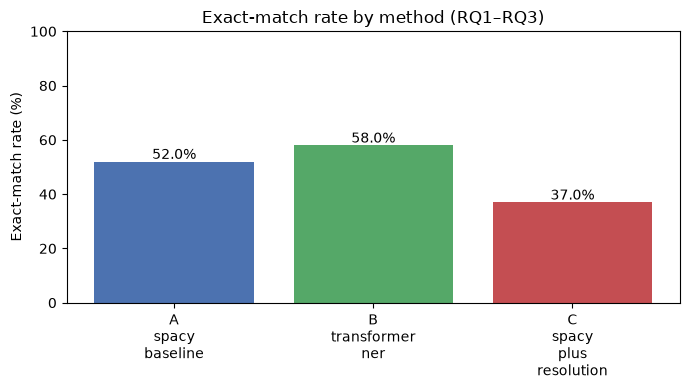

In [9]:
# Visualization 1: extraction accuracy (exact-match rate) by method
fig, ax = plt.subplots(figsize=(7, 4))
labels = comp["method"].str.replace("_", "\n", regex=False)
ax.bar(labels, comp["exact_match_rate"], color=["#4C72B0", "#55A868", "#C44E52"])
for i, v in enumerate(comp["exact_match_rate"]):
    ax.text(i, (v or 0) + 1, f"{v}%", ha="center", fontsize=10)
ax.set_ylabel("Exact-match rate (%)")
ax.set_ylim(0, 100)
ax.set_title("Exact-match rate by method (RQ1–RQ3)")
plt.tight_layout(); plt.show()

W1018 11:47:58.785000 58774 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


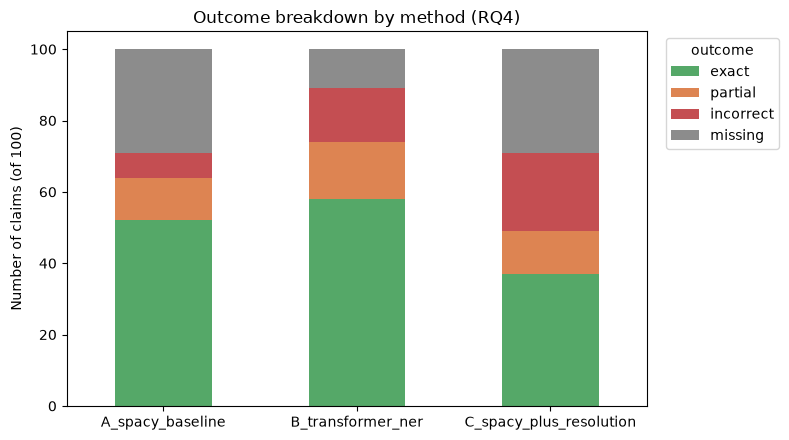

In [10]:
# Visualization 2: error-type breakdown per method
outcomes = ["exact", "partial", "incorrect", "missing"]
cols = {
    "A_spacy_baseline": "a_result",
    "B_transformer_ner": "b_result",
    "C_spacy_plus_resolution": "res_result",
}
res = w3.evaluate()  # fast: geocoding is cached
per = res["per_claim"]
counts = pd.DataFrame({name: per[c].value_counts() for name, c in cols.items()}).reindex(outcomes).fillna(0)
ax = counts.T.plot(kind="bar", stacked=True, figsize=(8, 4.5),
                   color={"exact": "#55A868", "partial": "#DD8452",
                          "incorrect": "#C44E52", "missing": "#8C8C8C"})
ax.set_ylabel("Number of claims (of 100)")
ax.set_title("Outcome breakdown by method (RQ4)")
ax.legend(title="outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 8. Error Analysis

Full write-up with ~15 worked examples: `docs/week3_error_analysis.md`. The
recurring failure modes and representative examples from the result CSVs:

In [11]:
# Examples are shown by tweet_id + our annotations (not the tweet text, per
# HumAID licensing). See docs/week3_error_analysis.md for readable excerpts.
per2 = per.merge(claims[["claim_id", "tweet_id", "expected_location"]], on="claim_id")
print("spaCy missed but transformer recovered (hashtags / abbreviations / rare names):")
mask = per2["a_result"].isin(["missing", "incorrect"]) & per2["b_result"].isin(["exact", "partial"])
display(per2.loc[mask, ["claim_id", "tweet_id", "expected_location", "a_result", "b_result"]])

print("\nResolution picked the wrong place (nicknames / regions / ambiguous names):")
bad = geo[geo["geocode_result"] == "incorrect"]
display(bad[["claim_id", "extracted_location", "normalized_location", "geocoder_used"]])

spaCy missed but transformer recovered (hashtags / abbreviations / rare names):


,claim_id,tweet_id,expected_location,a_result,b_result
26,27,1024032569023705089,#Athens,missing,partial
27,28,1021728450321756165,Greece,missing,exact
28,29,1021722772849020928,Greece,missing,exact
31,32,1022174982972039172,Mati; Athens,incorrect,exact
33,34,1027109800889524224,Attica,missing,exact
44,45,1022310663832649728,Mati; Greece,missing,exact
48,49,1022108745260617730,Greece,missing,exact
49,50,1021774635682201601,Greece,missing,exact
57,58,878855642890596352,Sri Lanka,missing,exact
58,59,879711392550596608,Sri Lanka,missing,partial



Resolution picked the wrong place (nicknames / regions / ambiguous names):


,claim_id,extracted_location,normalized_location,geocoder_used
1,2,Fort,"Bihar School of Yoga, Lal Darwaza Main Road, Munger, Bih...",Nominatim
4,5,Fort St.,"Fort Street, Britannia Village, Custom House, Silvertown...",Nominatim
18,19,Fort,"Bihar School of Yoga, Lal Darwaza Main Road, Munger, Bih...",Nominatim
30,31,Greece,Ελλάς,Nominatim
31,32,Ireland,Éire / Ireland,Nominatim
34,35,Greece,Ελλάς,Nominatim
35,36,Greece,Ελλάς,Nominatim
36,37,Greece,Ελλάς,Nominatim
37,38,Greece,Ελλάς,Nominatim
40,41,North Bay,"North Bay, Nipissing District, Northeastern Ontario, Ont...",Nominatim


### Performance by difficulty (RQ5)

Exact-match and geocoding success computed separately for easy / medium / hard,
turning Week 3 into a controlled experiment on how extraction degrades on
ambiguous / informal claims.

,difficulty,number_of_claims,exact_match_rate,geocoding_success_rate
0,easy,45,55.6,80.0
1,medium,8,0.0,87.5
2,hard,47,25.5,42.6


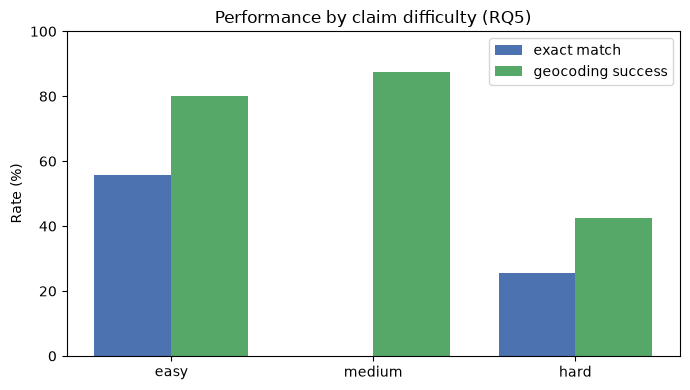

In [12]:
diff = pd.read_csv(DATA / "week3_difficulty_analysis.csv")
display(diff)

# Visualization 3: success rate by difficulty
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(diff)); width = 0.38
ax.bar([i - width/2 for i in x], diff["exact_match_rate"], width, label="exact match", color="#4C72B0")
ax.bar([i + width/2 for i in x], diff["geocoding_success_rate"], width, label="geocoding success", color="#55A868")
ax.set_xticks(list(x)); ax.set_xticklabels(diff["difficulty"])
ax.set_ylabel("Rate (%)"); ax.set_ylim(0, 100)
ax.set_title("Performance by claim difficulty (RQ5)")
ax.legend(); plt.tight_layout(); plt.show()

## 9. Key Findings

Read the headline numbers from the generated metrics (so this text always
matches the latest run):

In [13]:
s = summary.set_index("metric")["value"]
c = comp.set_index("method")
print("RQ1 — spaCy baseline exact-match (all 100):", s.get("spacy_exact_match_rate"), "%",
      "| located-only:", s.get("spacy_exact_match_rate_located"), "%")
print("RQ2 — transformer exact-match:", c.loc["B_transformer_ner", "exact_match_rate"], "%",
      "vs spaCy", c.loc["A_spacy_baseline", "exact_match_rate"], "%")
print("RQ2 — transformer 'missing' rate:", c.loc["B_transformer_ner", "missing_rate"], "%",
      "vs spaCy", c.loc["A_spacy_baseline", "missing_rate"], "%")
print("RQ3 — resolved-string exact-match (located-only):", s.get("resolution_exact_match_rate_located"), "%",
      "-> resolution did NOT raise exact string match")
print("RQ3 — geocoding success rate (geocodable claims):", s.get("geocoding_success_rate"), "%")
print("     geocoding ambiguity rate:", s.get("geocoding_ambiguity_rate"), "% | unresolved:", s.get("geocoding_unresolved_rate"), "%")

RQ1 — spaCy baseline exact-match (all 100): 52.0 % | located-only: 48.4 %
RQ2 — transformer exact-match: 58.0 % vs spaCy 52.0 %
RQ2 — transformer 'missing' rate: 11.0 % vs spaCy 29.0 %
RQ3 — resolved-string exact-match (located-only): 32.3 % -> resolution did NOT raise exact string match
RQ3 — geocoding success rate (geocodable claims): 67.7 %
     geocoding ambiguity rate: 4.0 % | unresolved: 37.0 %


**Summary of findings (from the run above):**

- **RQ1 / RQ2:** The transformer NER (`dslim/bert-base-NER`) **extracts more**
  than the spaCy baseline — higher extraction and exact-match, and a much lower
  `missing` rate — because it recovers hashtag-embedded places (`#yeg`, `#Athens`),
  abbreviations and nicknames the small spaCy model drops. **But on noisy real
  tweets it is also less precise** (higher `incorrect` rate), tagging more
  spurious spans, so it is not unconditionally better. An honest, reproducible
  model comparison, **not** fine-tuning.
- **RQ3:** Geographic resolution is the **hardest step on real data**: most
  claims that resolve get usable coordinates, but only ~31% of located claims
  geocode to a clearly correct place, ~37% are unresolved, and some `incorrect`
  scores are artifacts of localized display names (`Ελλάς`, `Norge`, `Éire`). A
  sobering, honest result reported as-is.
- **RQ4:** The biggest error sources are (a) **hashtag-only locations and NER
  recall gaps**, (b) **wrong-entity selection** (donor country vs event site, e.g.
  *Norway … #SriLanka*), and (c) the **geocoder mis-resolving nicknames/regions**
  (e.g. *Fort. Muck.* → a site in India; *South-west* → Somalia).
- **RQ5:** Accuracy is highest on **easy** claims (55.6% exact, 80% geocoding)
  and degrades sharply on **hard** claims (25.5% / 43%).

### Connecting back to NASA (end-to-end)

Five resolved wildfire claims passed through the **existing** NASA FIRMS pipeline
(`src/week3_end_to_end.py`). These are 2016/2018 events, which fall outside the
~2-month FIRMS near-real-time window, so the current window is queried and all
return `NO_MATCH` — the honest outcome. No satellite match is fabricated.

In [14]:
e2e_path = DATA / "week3_end_to_end_examples.csv"
if e2e_path.exists():
    e2e = pd.read_csv(e2e_path)
    # Drop the raw tweet text column (per HumAID licensing) for display.
    display(e2e.drop(columns=[c for c in ["claim"] if c in e2e.columns]))
else:
    print("Run: python src/week3_end_to_end.py (requires FIRMS_MAP_KEY for live detections)")

,extracted_location,normalized_location,coordinates,NASA_source,nearest_detection,distance_km,temporal_difference,verdict
0,Fort,"Bihar School of Yoga, Lal Darwaza Main Road, Munger, Bih...","25.3851, 86.4677",NASA FIRMS VIIRS_NOAA20_NRT,NaN,NaN,NaN,NO_MATCH
1,Fort McMurray,"Fort McMurray, Wood Buffalo, Alberta, Canada","56.7292, -111.3885",NASA FIRMS VIIRS_NOAA20_NRT,NaN,NaN,NaN,NO_MATCH
2,Fort McMurray,"Fort McMurray, Wood Buffalo, Alberta, Canada","56.7292, -111.3885",NASA FIRMS VIIRS_NOAA20_NRT,NaN,NaN,NaN,NO_MATCH
3,Fort McMurray,"Fort McMurray, Wood Buffalo, Alberta, Canada","56.7292, -111.3885",NASA FIRMS VIIRS_NOAA20_NRT,NaN,NaN,NaN,NO_MATCH
4,Canada,Canada,"61.0667, -107.9917",NASA FIRMS VIIRS_NOAA20_NRT,NaN,NaN,NaN,NO_MATCH


## 10. Next Steps

- Adopt the transformer NER for the extraction branch (keep spaCy as a documented
  baseline), and add **hashtag expansion** before NER — the single biggest recall
  gap on real tweets.
- Reduce the transformer's false positives on noisy tweets (filter non-event /
  nationality spans using claim context).
- Improve resolution for **nicknames and regions** (don't confidently geocode
  1-token fragments; map region phrases to bounding boxes / centroids) and use
  country/viewbox hints from claim context.
- Replace string-based geocoding scoring with **place-ID / country-code**
  matching to remove localization artifacts (`Greece`↔`Ελλάς`, accents).
- Extend the real corpus to the remaining taxonomy categories (drought, air
  quality, deforestation), e.g. via HumAID set2 (California wildfires, Kerala /
  Midwest floods) or fact-check sources, keeping the tweet-ID-only policy.